In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import numbers

from scipy.interpolate import interpn

import ipywidgets as widgets
from pathlib import Path

from thermal_loads_261119 import *

In [2]:
# environment settings: 
pd.set_option('display.max_column',None)
pd.set_option('display.max_rows',50)
pd.set_option('display.max_seq_items',None)
pd.set_option('display.max_colwidth', 500)
pd.set_option('expand_frame_repr', True)

np._core.arrayprint.set_printoptions(linewidth= 180)
np.set_printoptions(threshold=np.inf)

# Data

In [3]:
project = 'SCHOOL_A'

df0 = pd.read_csv("SCHOOL_A_niveau_0_components.csv")
df1 = pd.read_csv("SCHOOL_A_niveau_1_components.csv")
df2 = pd.read_csv("SCHOOL_A_niveau_2_components.csv")
df3 = pd.read_csv("SCHOOL_A_niveau_3_components.csv")

# Base internal temperatures of the different floors
t_in_values = [20, 20, 20, 20]

In [4]:
frames = [df0, df1, df2, df3]
wl, wd = gather_dataframes(frames)

df_tin = pd.DataFrame({'floor_number': np.arange(len(t_in_values)), 't_in': t_in_values}).set_index('floor_number')
df_tin

,t_in
floor_number,
0,20
1,20
2,20
3,20


#### Split foor and roof areas

In [5]:
# Split roof or floor area when floor/roof areas are not identical from one floor to another
split_floors = True

tolerance = 1e-6 # tolerance is expressed in m²

if split_floors:
    wl = wl.copy()
    wl = split_roof_floor(wl, tol = tolerance) 
    wl['area_m2'] = wl['area_m2'].round(3)

# Add column of identificators (id) for the detection of floor/roof interfaces : Floor/roof sharing the same area from one floor to another
wl = add_interface_id(wl)

wl.loc[pd.notna(wl['interface_id']) & (wl['id'] != wl['type'])][['floor_number', 'id', 'type', 'interface_id', 'area_m2']]

,floor_number,id,type,interface_id,area_m2
14,1,floor_1,floor,interface_0_1,53.194
15,1,floor_2,floor,ext_floor_1,102.811
16,1,roof_1,roof,interface_1_2,153.388
17,1,roof_2,roof,ext_roof_1,2.617
29,2,roof_1,roof,interface_2_3,148.969
30,2,roof_2,roof,ext_roof_2,4.419
42,3,roof_0,roof,ext_roof_3,112.776
43,3,roof_1,roof,ext_roof_3,101.950


#### Construction quality level (thermal bridges)
'A' : New building with certified minimization of thermal bridges  
'B' : New building compliant with general codes of practice  
'C' : Building with internal insulation interrupted by solid floor slabs  
'D' : Other buildings  

In [6]:
building_quality = 'D'

#### Heating system (stratification)   
'HAC' : Hot-air heating without additional destratification   
'HAD' : Hot-air heating with additional destratification   
'CRP' : Ceiling-mounted radiant panels   
'RTH' : Radiant tube heating   
'IRH' : Infrared radiant heater   
'SUR' : Integrated surface heat emission   
'RAD' : Radiators   
'NOT' : No heating system specified

In [7]:
heating_syst   = 'RAD'

#### General data

In [8]:
# Postal code
CP = 4000

# Infiltration rate at 50 Pa
n_50  = 6.0

# Windows U-value
U_wd  = 1.50  #[W/m2/K]

# Skylights U-value
U_sk  = 2.50  #[W/m2/K]

#### Ventilation

In [9]:
# Occupants requirements
q_occ_m3h  = 45 # Fresh air flow per occupant(m³/h.occ)

# Floor area per occupant
A_fl_occ = 3.5 # Meeting room value

# efficiency of ventilation system heat recovery exchanger
epsilon_hx  = 0.80 

#### Additional Power for Reheating

In [10]:
# Choose between EN12831 Annex F Tables 'F1' or 'F3'
rh_table = 'F1'

# 'L' : Lightweight structure, 'H' : Heavy structure
th_mass = 'H'

# Infiltration rate during setback time (min 0.1 vol/h, max 0.5 vol/h)
n_inf_setback = 0.5

# Heating set back duration (max 168 h for table 'F1')
time_setback_h = 14

# Reheat time in hours (min 0.5 h)
time_reheat_h = 6

# Minimum reheat factor (W/m² of floor heated area)
f_rh_min = 10 # W/m²

#### Wall types layers

In [11]:
materials_list = []

materials_list.append({"material":'concrete_bloc'      ,"lambda":1.36,"rho":2000,"c":1000})
materials_list.append({"material":'insulation'         ,"lambda":0.026,"rho":80, "c":840})
materials_list.append({"material":'reinforced_concrete',"lambda":2.30,"rho":2400,"c":1000})
materials_list.append({"material":'concrete'           ,"lambda":2.10,"rho":2400,"c":1000})
materials_list.append({"material":'brick'              ,"lambda":1.59,"rho":2200,"c":1000})
materials_list.append({"material":'screed'             ,"lambda":1.40,"rho":2000,"c":1000})
materials_list.append({"material":'wood'               ,"lambda":0.13, "rho":600, "c":1600})
materials_list.append({"material":'foamglass'          ,"lambda":0.055,"rho":150,"c":1000})
materials_list.append({"material":'plaster_panel'      ,"lambda":0.32,"rho":1200,"c":1000})
materials_list.append({"material":'EPS_board'          ,"lambda":0.034,"rho":25, "c":1300})
materials_list.append({"material":'glass_wool'         ,"lambda":0.036,"rho":28,  "c":1030})
materials_list.append({"material":'rock_wool'          ,"lambda":0.035,"rho":115, "c":1030})
materials_list.append({"material":'wood_wool'          ,"lambda":0.039,"rho":48,  "c":2100})
materials_list.append({"material":'air_30mm_horizontal',"lambda":0.180,"rho":1.2, "c":1000})
materials_list.append({"material":'air_40mm_horizontal',"lambda":0.240,"rho":1.2, "c":1000})
materials_list.append({"material":'air_80mm_horizontal' ,"lambda":0.444,"rho":1.2, "c":1000})

# materials = pd.DataFrame(materials_list)

# Add composite material
# Data = material list, names of the first and second materials, widths of the first and second materials
composite_material(materials_list, 'wood_wool_complex', 'wood_wool', 'wood', 0.4, 0.035)
composite_material(materials_list, 'rock_wool_complex', 'rock_wool', 'wood', 0.4, 0.065)

materials = pd.DataFrame(materials_list)
materials = materials.set_index('material')

# Wall layers from indoor to outdoor

wt_layers = \
[
 ('wall_brick', 0, 0.45, 'brick'),

 ('wall_brick_isol', 0, 0.025, 'plaster_panel'),  # M8 - Third floor
 ('wall_brick_isol', 1, 0.030, 'wood_wool_complex'),
 ('wall_brick_isol', 2, 0.240, 'rock_wool_complex'),
 ('wall_brick_isol', 3, 0.018, 'wood'),
 ('wall_brick_isol', 4, 0.450, 'brick'),

 ('party_wall', 1, 0.450, 'brick'),            # M3 - To sport hall
 ('party_wall', 2, 0.030, 'air_30mm_horizontal'),
 ('party_wall', 3, 0.120, 'wood_wool_complex'),
 ('party_wall', 4, 0.018, 'wood'),
 ('party_wall', 5, 0.025, 'plaster_panel'),

 ('wall_int',   0, 0.19, 'concrete_bloc'),

 ('partition',  0, 0.025, 'plaster_panel'),
 ('partition',  1, 0.080, 'air_80mm_horizontal'),
 ('partition',  2, 0.025, 'plaster_panel'),
 
 ('roof'    ,   0, 0.025, 'plaster_panel'), # P2
 ('roof'    ,   1, 0.240, 'rock_wool_complex'),

 ('floor_gr',   0, 0.08, 'concrete'),

 ('floor_int',  0, 0.30, 'concrete'), 

 ('door_int'    , 0, 0.005, 'wood'),
 ('door_int'    , 1, 0.040, 'air_40mm_horizontal'),
 ('door_int'    , 2, 0.005, 'wood'),

 ('door_ext'    , 0, 0.05, 'wood'),
]

wt_layers = pd.DataFrame(wt_layers, columns=('wall_type', 'layer', 'thickness', 'material'))
wt_layers = wt_layers.sort_values(['wall_type', 'layer'])
wt_layers = wt_layers.set_index('wall_type')

#### Wall type specificities

In [12]:
wall_types = wt_layers.index.unique()
flag_cols = ['thermal_bridges', 'external_clading', 'adjacent_entity', 'ground_contact']

get_flags = flag_form(wall_types, flag_cols, project + '_env_wt.csv')

Output()

In [13]:
wt_env = get_flags()          # index = wall_types, 4 boolean columns
# wt_env

In [14]:
options_w = sorted(set(wt_layers.index)) + ['']
options_t = ['t_ext', 't_min', 't_avg'] + ['']

#### Walls: wall types and environmental temperatures

##### Floor 0

In [15]:
wlv0 = wl.loc[(wl['type'] == 'wall') & (wl['floor_number'] == 0)]
keys_wlv0 = ['orientation', 'type']
get_wlv0 = env_form(wlv0, keys_wlv0, project + '_env_wlv0.csv', options_w, options_t)

Output()

In [16]:
wlv0_filled = wlv0.merge(get_wlv0(), on=keys_wlv0, how='left')
# wlv0_filled

##### Floors 1 and 2

In [17]:
wlv = wl.loc[(wl['type'] == 'wall') & (wl['floor_number'] != 0) & (wl['floor_number'] != 3)]
keys_wlv = ['orientation', 'floor_number', 'type', 'width_m', 'height_m']
get_wlv = env_form(wlv, keys_wlv, project + '_env_wlv.csv', options_w, options_t)

Output()

In [18]:
wlv_filled = wlv.merge(get_wlv(), on=keys_wlv, how='left')
# wlv_filled

##### Floor 3

In [19]:
wlv3 = wl.loc[(wl['type'] == 'wall') & (wl['floor_number'] == 3)]
keys_wlv3 = ['orientation', 'type', 'width_m', 'height_m', 'sill_height_m']
get_wlv3 = env_form(wlv3, keys_wlv3, project + '_env_wlv3.csv', options_w, options_t)

Output()

In [20]:
wlv3_filled = wlv3.merge(get_wlv3(), on=keys_wlv3, how='left')
# wlv3_filled

#### Panels: wall types and environmental temperatures

In [21]:
wlp = wl.loc[wl['type'] == 'panel']
keys_wlp = ['orientation', 'floor_number', 'id', 'width_m', 'height_m', 'sill_height_m']
get_wlp = env_form(wlp, keys_wlp, project + '_env_wlp.csv', options_w, options_t)

Output()

In [22]:
wlp_filled = wlp.merge(get_wlp(), on=keys_wlp, how='left')
# wlp_filled 

#### Floors and roofs: wall types and environmental temperatures

##### Interfaces between floors

In [23]:
wli = wl.loc[(wl['type'].isin(['floor', 'roof'])) & (wl['interface_id'].str.contains('interface', na=False))]
keys_wli = ['interface_id']
get_wli = env_wt_form(wli, keys_wli, project + '_env_wli.csv', options_w)

Output()

In [24]:
wli_filled = wli.merge(get_wli(), on=keys_wli, how='left')
wli_filled = add_t_env(wli_filled, df_tin) 
# wli_filled

##### Floors and roofs not shared between floors

In [25]:
wlh = wl.loc[(wl['type'].isin(['floor', 'roof'])) & (~wl['interface_id'].str.contains('interface', na=False))]
keys_wlh = ['floor_number', 'interface_id', 'area_m2']
get_wlh = env_form(wlh, keys_wlh, project + '_env_wlh.csv', options_w, options_t)

Output()

In [26]:
wlh_filled = wlh.merge(get_wlh(), on=keys_wlh, how='left')
# wlh_filled

In [27]:
wl_filled = pd.concat([wlv0_filled, wlv_filled, wlv3_filled, wlp_filled, wli_filled, wlh_filled])
# wl_filled

# Compute and Results

In [28]:
# dfw  : wall data, parameters and heat transmission losses 
# dfwT : heat transmission losses by wall
# dfwtT: heat transmission losses by wall type 
# dfzT: heat transmission losses by zonez and breakdown according to vertical walls, horizontal walls and windows
# dfzpPHI: heat losses and loads by zone with total emission and total production rows
# dfzPHI: heat losses and loads by zone
# dffPHI: heat losses and loads by facade
# dffv : heat losses and loads by facade and by zone


gen_data  = [df_tin, building_quality, heating_syst, CP, n_50, U_wd, U_sk]
vent_data = [q_occ_m3h, A_fl_occ, epsilon_hx]
ctrl_data = [rh_table, th_mass, n_inf_setback, time_setback_h, time_reheat_h, f_rh_min]

dfv          = ventilation_losses(gen_data, vent_data, wl)
dfwt, dfw    = tansmission_losses(gen_data, materials, wt_layers, wt_env, wl_filled, wd, dfv)
dfz          = reheating_loads(gen_data, ctrl_data, dfv, dfw)

dfwT, dfwtT, dfzT, dfzPHI, dfzpPHI  = thermal_loads_by_zone(dfv, dfw, dfz, wt_env)
dffv, dffPHI = thermal_loads_by_facade(dfv, dfw, dfz, wt_env, dfzPHI)

df_gen_data, df_ctrl_data, dfv, dfwt, dfw, dfwT, dfwtT, dfzT, dfzPHI, dfzpPHI= \
                display_tables(gen_data, ctrl_data, dfv, dfw, dfwt, dfwT, dfwtT, dfzT, dfzpPHI, dfzPHI, dffv, dffPHI)

# Graph

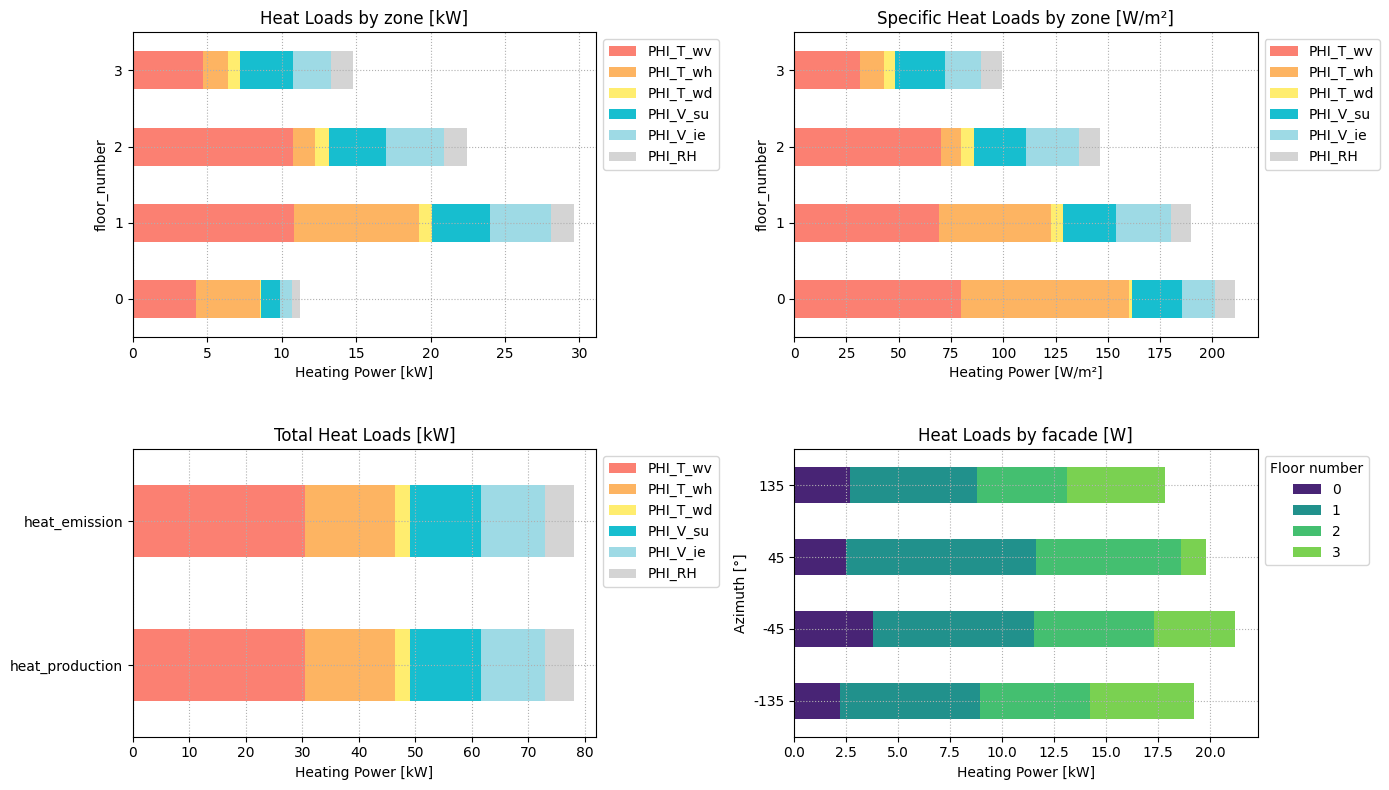

In [29]:
fig, axes = plot_heat_loads(
    dfPHI=dfzpPHI,
    dfv=dfv,
    dffv=dffv,
    display_total=False,
    reverse_order=False
)

# Tables

In [30]:
# Display style for the dataframes
styles = [dict(selector="caption",
                       props=[("text-align", "middle"),
                              ("font-size", "110%"),
                              ("font-weight", "bold"),
                              ("color", 'black'),
                              ("padding-bottom", "10px"),
                              ("white-space", "nowrap")
                             ])]

#### Transmission by wall types

#### Transmission by zone and wall categories

#### Heat Loads by zone and for production 

In [31]:
bold_cols = ['PHI_T', 'PHI_V', 'PHI_TOT', 'PHI_HL']
bold_cols = [col for col in dfzpPHI.columns if col.startswith(tuple([x + ' ' for x in bold_cols]))]

dfzpPHI.style \
    .format("{:.0f}") \
    .set_properties(subset=bold_cols, **{"font-weight": "bold"}) \
    .set_caption("Transmission Ventilation and Total Heat losses - Heat Loads by zone [W]") \
    .set_table_styles(styles)

,PHI_T_wv [W],PHI_T_wh [W],PHI_T_wd [W],PHI_T [W],PHI_V_su [W],PHI_V_ie [W],PHI_V [W],PHI_TOT [W],PHI_RH [W],PHI_HL [W]
floor_number,,,,,,,,,,
0,4232,4294,59,8585,1277,834,2111,10695,532,11227
1,10835,8364,870,20069,3911,4107,8018,28087,1560,29647
2,10757,1451,966,13173,3835,3884,7719,20892,1534,22426
3,4683,1736,777,7195,3575,2559,6134,13330,1490,14819
heat_emission,30506,15845,2671,49022,12598,11384,23982,73004,5116,78120
heat_production,30506,15845,2671,49022,12598,11384,23982,73004,5116,78120


#### By facade

In [32]:
bold_cols = ['PHI_HL']
bold_cols = [col for col in dffPHI.columns if col.startswith(tuple([x + ' ' for x in bold_cols]))]

dffPHI.style \
    .format("{:.0f}") \
    .set_properties(subset=bold_cols, **{"font-weight": "bold"}) \
    .set_caption("Heat Losses and Heat Loads by facade [W]") \
    .set_table_styles(styles)

,PHI_TOT [W],PHI_HL [W]
azimuth_deg,,
-135,17850,19214
-45,19904,21230
45,18713,19819
135,16537,17857


#### Save to Excel

In [33]:
with pd.ExcelWriter(project + "_output.xlsx") as writer: 

    # DATA
    
    # General data
    df_gen_data.to_excel(writer, sheet_name='general_data')

    # Reheat data
    df_ctrl_data.to_excel(writer, sheet_name='control_data') 

    # Materials data
    materials.to_excel(writer, sheet_name='materials_data')

    # Wall types layers data
    wt_layers.to_excel(writer, sheet_name='wall_types_layers_data')

    # Wall types environmental data
    wt_env.to_excel(writer, sheet_name='wall_types_env_data')

    # Walls data
    wl.to_excel(writer, sheet_name='wall_data')

    # Windows data
    wd.to_excel(writer, sheet_name='windows_data')

    # Ventilation data
    dfv.to_excel(writer, sheet_name='ventilation_data') 


    # RESULTS

    # dfwt : Walls thicknesses [m] and conductive resistance [m²K/W]
    dfwt.round(2).to_excel(writer, sheet_name='walls_types') 
    
    # dfw : Walls Areas [m²] - Temperature Factors - U_values [W/m²K] - Heat transmission losses [W]
    dfw.to_excel(writer, sheet_name='walls') 

    # dfwtT: Walls Areas [m²] - Heat transmission losses [W] by zone and wall type
    dfwtT.to_excel(writer, sheet_name='TR_by_walls_types_zone') 

    # dfzT: Wall Areas [m²] - Heat transmission losses [W] by zone
    dfzT.to_excel(writer, sheet_name='TR_by_zone') 

    # dfzPHI  : Heat losses and heat loads by zone [W] (emission and production)
    dfzPHI.to_excel(writer, sheet_name='PHI_by_zone') 

    # dffPHI : Heat losses and loads by facade [W]
    dffPHI.astype(int).to_excel(writer, sheet_name='PHI_by_facade') 